# Vegetación saludable y tipos de cultivo con Landsat

**Laboratorio N°1 – Procesamiento de Imágenes Multiespectrales con Landsat 8** · Fundamentos del Procesamiento Digital de Imágenes · Grupo N°4
Actividad 3 desarrollada por Lucas Dutra.

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/BrianAranda/Informes_FDPI/blob/lab1/code/ejercicio_3/vegetacion_cultivos.ipynb)

**Consigna (actividad 3).** Identificar áreas con vegetación densa y saludable y diferenciar entre distintos tipos de cultivos. Bandas de interés: 3 (verde), 5 (infrarrojo cercano, **NIR**) y 6 (infrarrojo de onda corta 1, **SWIR 1**). Se arma una composición RGB (*Red, Green, Blue*) que represente el objetivo, se justifica la selección de bandas, se aplica mejora de contraste y se analiza si la resolución espacial alcanza.

**Además de la consigna:** la elección de bandas se comprueba con mediciones sobre áreas de muestra, se agrupan los píxeles sin supervisión para verificar la separación, y se clasifica la escena completa para ubicar los objetivos.

**Escena** (carpeta de Drive de la cátedra): Landsat 9 (OLI-2), órbita 224/079, 03/04/2024, 0 % de nubes, reflectancia de superficie de nivel 2.

**Regiones de estudio** (ROI, *Region of Interest*; cuadrados de 30 km de lado):

| ROI | Qué aporta |
|---|---|
| A. Itapúa (Paraguay) | Agricultura mecanizada en lotes grandes: tipos y estados de cultivo |
| B. Apóstoles (Misiones) | Yerbales, forestaciones, pastizales y monte: vegetación implantada y herbácea |
| C. Sierra Central de Misiones | Selva paranaense continua sobre relieve: la vegetación más densa y saludable |

## 1. Configuración

El notebook no necesita ningún otro archivo del repositorio: funciona igual en Colab y en local. La escena (unos 600 MB) no está en el repositorio. Si no encuentra `datos/Sur_Misiones_20240403/`, `preparar_escena` la descarga de la carpeta de Drive de la cátedra.

In [1]:
import zipfile
from itertools import combinations
from pathlib import Path

import numpy as np
import cv2
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Patch
from matplotlib.transforms import Bbox

cv2.utils.logging.setLogLevel(cv2.utils.logging.LOG_LEVEL_ERROR)   # avisos de etiquetas GeoTIFF

# --- Carpetas y escena ---
DIR_DATOS = Path("datos")                  # la escena no se sube al repositorio (.gitignore)
DIR_FIG = Path("../../img/ejercicio3")     # figuras del informe
ESCENA, ID_DRIVE = "Sur_Misiones_20240403", "1wP_81y_e-eaHdWW7Up2DUnI2P5l1_0HT"


def preparar_escena(nombre=ESCENA):
    # Devuelve la carpeta de la escena. Si falta, descomprime el zip; si falta el zip, lo descarga.
    carpeta = DIR_DATOS / nombre
    if carpeta.is_dir():
        return carpeta
    DIR_DATOS.mkdir(exist_ok=True)
    archivo = DIR_DATOS / f"{nombre}.zip"
    if not archivo.exists():
        import gdown   # viene instalado en Colab; en local: pip install gdown
        gdown.download(f"https://drive.google.com/uc?id={ID_DRIVE}", str(archivo), quiet=False)
    with zipfile.ZipFile(archivo) as z:
        z.extractall(DIR_DATOS)
    return carpeta


# --- Figuras: misma tipografía y ancho que el informe ---
# Exportar las figuras a DIR_FIG queda apagado para no modificar las del repositorio al ejecutar.
EXPORTAR_FIGURAS = False
%config InlineBackend.figure_formats = ["jpeg"]
%config InlineBackend.print_figure_kwargs = {"bbox_inches": "tight", "pil_kwargs": {"quality": 85}}
ANCHO = 483.69687 / 72.27   # \linewidth del informe en pulgadas
plt.rcParams.update({
    "font.family": "serif", "font.serif": ["Times New Roman", "Times", "Liberation Serif", "DejaVu Serif"],
    "mathtext.fontset": "stix", "font.size": 10, "axes.titlesize": 10, "legend.fontsize": 9,
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight", "grid.alpha": 0.4,
    "figure.constrained_layout.use": True,
    "figure.constrained_layout.w_pad": 0.02, "figure.constrained_layout.h_pad": 0.02,
    "figure.constrained_layout.wspace": 0.02, "figure.constrained_layout.hspace": 0.02,
})


def guardar(fig, nombre, formato="jpg"):
    # Exporta sin título general (va en el caption de LaTeX). Imágenes satelitales en JPEG, gráficos en PDF.
    if not EXPORTAR_FIGURAS:
        return
    DIR_FIG.mkdir(parents=True, exist_ok=True)
    sup = fig.get_suptitle(); fig.suptitle("")
    fig.canvas.draw()
    c = fig.get_tightbbox(fig.canvas.get_renderer())
    caja = Bbox.from_extents(0, c.y0 - 0.02, fig.get_figwidth(), c.y1 + 0.02)
    extra = {"pil_kwargs": {"quality": 92}} if formato == "jpg" else {"metadata": {"CreationDate": None}}
    fig.savefig(DIR_FIG / f"{nombre}.{formato}", bbox_inches=caja, **extra)
    fig.suptitle(sup)


def mostrar_img(ax, img, rotulo="", **kw):
    # Imagen sin ejes, con el rótulo "(a) ..." debajo
    ax.imshow(img, **kw); ax.set_xticks([]); ax.set_yticks([]); ax.set_xlabel(rotulo)

### Lectura de la escena

Cada píxel guarda un número digital (**DN**, entero de 16 bits) que se convierte a **reflectancia de superficie** con $\rho = DN \cdot 2{,}75\times10^{-5} - 0{,}2$; $DN = 0$ es relleno (fuera de la huella del satélite). Las seis bandas B2–B7 se leen completas (≈ 120 MB cada una). Para la escena completa se usa un píxel de cada dos (60 m).

In [2]:
CARPETA = preparar_escena()
BANDAS, PASO = (2, 3, 4, 5, 6, 7), 2
FULL = {b: cv2.imread(str(next(CARPETA.glob(f"*_SR_B{b}.TIF"))), cv2.IMREAD_UNCHANGED) for b in BANDAS}
REC = {"A": (1614, 1993, 1000), "B": (5303, 1628, 1000), "C": (1300, 5700, 1000)}   # fila, columna, lado [px]
E = {b: FULL[b][::PASO, ::PASO] for b in BANDAS}
R = {k: {b: FULL[b][f:f + n, c:c + n] for b in BANDAS} for k, (f, c, n) in REC.items()}
VAL_E = np.all([E[b] > 0 for b in BANDAS], 0)
LIM = {b: np.percentile(E[b][VAL_E], [2, 98]) for b in BANDAS}   # límites de contraste comunes a toda la escena
print(f"Píxeles sin dato: {(1 - VAL_E.mean()) * 100:.0f} %")
print("Percentil 2 (cuentas) solo con píxeles válidos: " + ", ".join(f"B{b} {LIM[b][0]:.0f}" for b in (3, 5, 6)) +
      f" | incluyendo el relleno: {np.percentile(E[3], 2):.0f}")


def rho(dn): return np.where(dn > 0, dn * 2.75e-5 - 0.2, np.nan).astype(np.float32)
def indice(a, b):
    with np.errstate(all="ignore"): return np.clip((a - b) / (a + b), -1, 1)
def estirar(dn, lo, hi): return np.round(np.clip((dn.astype(np.float32) - lo) / (hi - lo), 0, 1) * 255).astype(np.uint8)
def rgb(d, r, g, b, lim=None):
    lim = lim or LIM
    return np.dstack([estirar(d[x], *lim[x]) for x in (r, g, b)]) * (d[3] > 0)[..., None]
def ventana(f, c, h, w): return {b: FULL[b][f:f + h, c:c + w] for b in BANDAS}

Píxeles sin dato: 33 %
Percentil 2 (cuentas) solo con píxeles válidos: B3 8079, B5 7781, B6 7406 | incluyendo el relleno: 0


## 2. Zonas y áreas de muestra

Además de las tres ROI se marcaron, por fotointerpretación, **áreas de muestra** de cada cobertura: rectángulos chicos (0,2 a 1,4 km²) sobre una única cobertura, para medir su respuesta espectral sin mezclas. Una misma cobertura puede variar mucho de un lugar a otro, así que las coberturas con más variación interna llevan más muestras: la **selva**, cuatro áreas, tres de ellas en la sierra con laderas al sol y en sombra, y el **pinar**, cuatro plantaciones distintas (reconocibles por sus bloques rectangulares con cortafuegos), cada área dentro de un solo compartimento, sin cortafuegos. Los estados de cultivo se muestrearon con uno a tres lotes. Estas mismas áreas se usan para la firma espectral, la separabilidad, la diferencia de color y el entrenamiento de la clasificación (sección 7).

Agua                  3 áreas,   675 píxeles
Urbano                2 áreas,   800 píxeles
Rastrojo / suelo      2 áreas,   450 píxeles
Vegetación rala       1 áreas,   300 píxeles
Pastizal              2 áreas,   850 píxeles
Cultivo verde medio   1 áreas,   225 píxeles
Cultivo vigoroso      3 áreas,   950 píxeles
Selva                 4 áreas,  5425 píxeles
Pinar                 4 áreas,  1252 píxeles


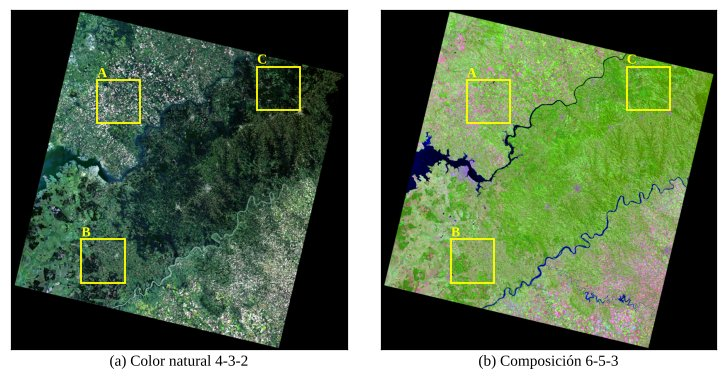

In [3]:
MUESTRAS = {   # áreas de muestra por clase: fila, columna, alto, ancho en la escena
    "Agua": [(3471, 1947, 15, 15), (5549, 4390, 15, 15), (6709, 5571, 15, 15)],
    "Urbano": [(3650, 1973, 20, 20), (4113, 4538, 20, 20)],
    "Rastrojo / suelo": [(1477, 3690, 15, 15), (6985, 5026, 15, 15)],
    "Vegetación rala": [(6122, 931, 25, 12)],                       # tala reciente
    "Pastizal": [(5607, 800, 25, 25), (5057, 1478, 15, 15)],
    "Cultivo verde medio": [(1528, 3536, 15, 15)],
    "Cultivo vigoroso": [(1645, 3508, 20, 25), (1048, 4512, 15, 15), (6861, 5707, 15, 15)],
    "Selva": [(2436, 5213, 25, 25), (2200, 6400, 40, 40), (1850, 6250, 40, 40), (1650, 6450, 40, 40)],
    "Pinar": [(6093, 795, 16, 16), (5360, 520, 20, 20), (6243, 792, 14, 14), (5420, 1860, 20, 20)]}
CL = list(MUESTRAS)
COB = ["Selva", "Pinar", "Vegetación rala", "Pastizal", "Cultivo vigoroso", "Cultivo verde medio", "Rastrojo / suelo"]
COL = dict(zip(COB, ["#166534", "#0f766e", "#c2410c", "#a3a33a", "#65a30d", "#4ade80", "#db2777"]))
MUE = {c: {b: np.concatenate([rho(ventana(*v)[b]).ravel() for v in MUESTRAS[c]]) for b in BANDAS} for c in CL}
def X3m(c): return np.stack([MUE[c][b] for b in (3, 5, 6)], 1)   # píxeles de muestra de una clase en B3, B5 y B6
for c in CL:
    print(f"{c:<22}{len(MUESTRAS[c])} áreas, {len(MUE[c][3]):>5} píxeles")

S = 3   # la vista general se submuestrea otra vez (180 m) para que la figura pese poco
fig, ejes = plt.subplots(1, 2, figsize=(ANCHO, 3.3))
for ax, bandas, rot in [(ejes[0], (4, 3, 2), "(a) Color natural 4-3-2"), (ejes[1], (6, 5, 3), "(b) Composición 6-5-3")]:
    mostrar_img(ax, rgb({b: E[b][::S, ::S] for b in BANDAS}, *bandas), rot)
    for k, (f, c, n) in REC.items():
        ax.add_patch(Rectangle((c / PASO / S, f / PASO / S), n / PASO / S, n / PASO / S, fill=False, ec="yellow", lw=1.2))
        ax.text(c / PASO / S, f / PASO / S - 12, k, color="yellow", fontweight="bold", fontsize=9)
guardar(fig, "escena"); plt.show()

Vista ampliada de cada zona en color natural (R = B4, G = B3, B = B2), con los mismos límites de contraste de toda la escena y a resolución completa (30 m).

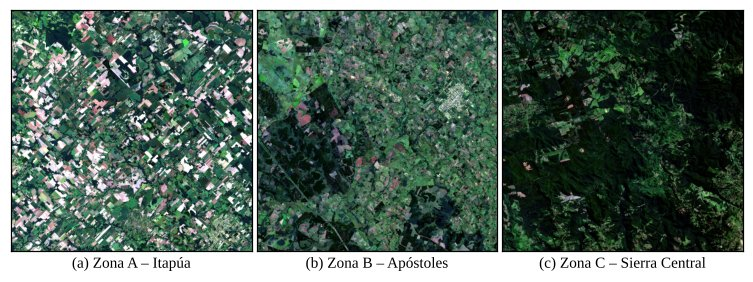

In [4]:
fig, ejes = plt.subplots(1, 3, figsize=(ANCHO, 2.5))
for ax, letra, (k, nombre) in zip(ejes, "abc", {"A": "Itapúa", "B": "Apóstoles", "C": "Sierra Central"}.items()):
    mostrar_img(ax, rgb(R[k], 4, 3, 2), f"({letra}) Zona {k} – {nombre}")
guardar(fig, "zonas_rgb"); plt.show()

Recorte de 3 × 3 km alrededor de cada área de muestra en la composición 6-5-3 (sección 4), con el área marcada en amarillo, para ver qué se tomó como muestra.

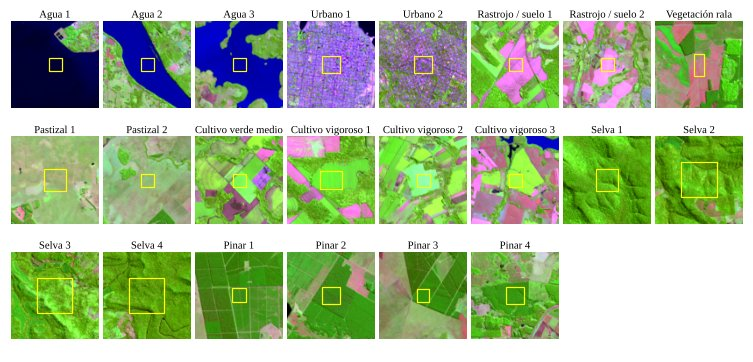

In [5]:
L = 100   # lado del recorte [px]
items = [(c, i + 1, v) for c in CL for i, v in enumerate(MUESTRAS[c])]
fig, ejes = plt.subplots(3, 8, figsize=(ANCHO, 3.15))
for ax in ejes.ravel(): ax.axis("off")
for ax, (c, i, (f, cc, h, w)) in zip(ejes.ravel(), items):
    f0_, c0_ = f + h // 2 - L // 2, cc + w // 2 - L // 2
    ax.imshow(rgb(ventana(f0_, c0_, L, L), 6, 5, 3))
    ax.add_patch(Rectangle((cc - c0_ - .5, f - f0_ - .5), w, h, fill=False, ec="yellow", lw=.8))
    ax.set_title(f"{c} {i}" if len(MUESTRAS[c]) > 1 else c, fontsize=7, pad=2)
guardar(fig, "muestras"); plt.show()

## 3. Selección de bandas

- **B5 (NIR):** la estructura interna de la hoja refleja fuertemente el infrarrojo cercano. Mide *vigor*.
- **B6 (SWIR 1):** el agua de la hoja absorbe en esta región. Separa lo húmedo de lo seco y la vegetación del suelo.
- **B3 (verde):** pico de reflectancia de la clorofila en el visible.

Se mide la **firma espectral** de cada cobertura (reflectancia media de sus píxeles de muestra en cada banda) y la **separabilidad** entre pares de coberturas, $S = |\mu_1-\mu_2|/(\sigma_1+\sigma_2)$, donde μ y σ son la media y el desvío de la reflectancia de los píxeles de muestra de cada cobertura. El numerador es la distancia entre las coberturas y el denominador su dispersión: con S = 1 los rangos μ ± σ apenas se tocan, con S > 1 casi no se solapan y con S < 0,5 se confunden. Es el índice de discriminación *M* de Kaufman y Remer (1994), una versión simplificada de la razón de Fisher del ejercicio 2.

S mide **una variable por vez**, pero la composición y la clasificación usan las tres bandas juntas. Para medir la separación combinada se usa el **discriminante lineal de Fisher**: la combinación de bandas $w^\top x$ que hace máxima la separación, con $w = (\Sigma_1 + \Sigma_2)^{-1}(\mu_1 - \mu_2)$ (Σ: covarianza de cada cobertura), y sobre ella se calcula S. Como referencia se agrega el **NDVI** (*Normalized Difference Vegetation Index*), $(B5-B4)/(B5+B4)$.

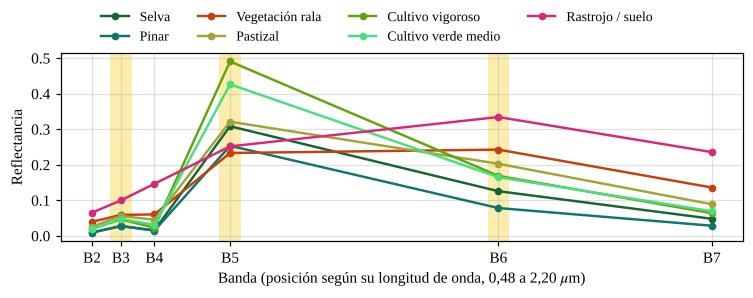

Firma media                B3     B5     B6   NDVI
Selva                   0.028  0.308  0.126   0.90
Pinar                   0.028  0.253  0.078   0.89
Vegetación rala         0.059  0.233  0.243   0.59
Pastizal                0.056  0.321  0.203   0.75
Cultivo vigoroso        0.046  0.491  0.169   0.91
Cultivo verde medio     0.048  0.426  0.165   0.86
Rastrojo / suelo        0.100  0.252  0.334   0.26

Separabilidad S                               B3    B5    B6   NDVI  B3+B5+B6
Selva vs Pinar                              0.00  0.77  1.54   0.38      2.93
Selva vs Pastizal                           3.61  0.18  2.08   3.62      5.24
Selva vs Cultivo vigoroso                   0.98  1.54  0.82   0.39      2.08
Cultivo vigoroso vs Cultivo verde medio     0.10  0.63  0.10   0.93      1.16
Pastizal vs Cultivo verde medio             1.78  1.85  1.74   1.46      2.64

Con una sola área de selva y una de pinar: S en B5 = 1.16


In [6]:
L = {2: .482, 3: .562, 4: .655, 5: .865, 6: 1.609, 7: 2.201}   # longitud de onda central [µm]
fig, ax = plt.subplots(figsize=(ANCHO, 2.6))
for b in (3, 5, 6): ax.axvspan(L[b] - .03, L[b] + .03, color="#fde68a", alpha=.7, lw=0)
for p in COB:
    ax.plot(list(L.values()), [np.nanmean(MUE[p][b]) for b in L], "o-", color=COL[p], label=p, lw=1.6, ms=4)
ax.set_xticks(list(L.values()), [f"B{b}" for b in L]); ax.set_ylabel("Reflectancia"); ax.grid(True)
ax.set_xlabel(r"Banda (posición según su longitud de onda, 0,48 a 2,20 $\mu$m)")
fig.legend(ncol=4, loc="outside upper center", frameon=False)
guardar(fig, "firmas", "pdf"); plt.show()

print(f"{'Firma media':<22}{'B3':>7}{'B5':>7}{'B6':>7}{'NDVI':>7}")
for p in COB:
    print(f"{p:<22}" + "".join(f"{np.nanmean(MUE[p][x]):>7.3f}" for x in (3, 5, 6)) + f"{np.nanmean(indice(MUE[p][5], MUE[p][4])):>7.2f}")
print()
sep = lambda a, b: abs(np.nanmean(a) - np.nanmean(b)) / (np.nanstd(a) + np.nanstd(b))
def fisher(Xa, Xb):   # S sobre la combinación lineal de variables que más separa las dos clases
    w = np.linalg.solve(np.cov(Xa.T) + np.cov(Xb.T), Xa.mean(0) - Xb.mean(0))
    return sep(Xa @ w, Xb @ w)
PARES = [("Selva", "Pinar"), ("Selva", "Pastizal"), ("Selva", "Cultivo vigoroso"),
         ("Cultivo vigoroso", "Cultivo verde medio"), ("Pastizal", "Cultivo verde medio")]
print(f"{'Separabilidad S':<42}{'B3':>6}{'B5':>6}{'B6':>6}{'NDVI':>7}{'B3+B5+B6':>10}")
for a, b in PARES:
    nd = [indice(MUE[x][5], MUE[x][4]) for x in (a, b)]
    print(f"{a + ' vs ' + b:<42}" + "".join(f"{sep(MUE[a][x], MUE[b][x]):>6.2f}" for x in (3, 5, 6)) +
          f"{sep(*nd):>7.2f}{fisher(X3m(a), X3m(b)):>10.2f}")
pa, pb = MUESTRAS["Selva"][0], MUESTRAS["Pinar"][0]
print(f"\nCon una sola área de selva y una de pinar: S en B5 = {sep(rho(ventana(*pa)[5]), rho(ventana(*pb)[5])):.2f}")

**Resultado.**

- **Ninguna banda sola separa todos los pares.** B5 (NIR) separa la selva del cultivo vigoroso (S = 1,54), pero no del pastizal (0,18): a fin del verano los dos reflejan ≈ 0,31. B6 (SWIR 1) es la mejor para selva–pinar (1,54) y selva–pastizal (2,08). B3 separa la selva del pastizal (3,61), pero no del pinar (0,00).
- **Los estados de cultivo son el par más difícil:** ninguna banda pasa de 0,63 entre cultivo vigoroso y verde medio.
- El **NDVI se satura** en la vegetación densa: selva 0,90 y cultivo vigoroso 0,91 (S = 0,39).
- **Combinadas**, las tres bandas separan todos los pares: S va de 1,16 (estados de cultivo) a 5,24 (selva–pastizal), y selva–pinar llega a 2,93.

**Conclusión.** Cada banda resuelve pares distintos: B5 la estructura del dosel, B6 el contenido de agua y B3 los tonos de verde. La separación completa aparece solo al combinarlas, y esa es la justificación para usar las tres. La separabilidad depende de que las muestras representen toda la variación de cada cobertura: con una sola área de selva y una de pinar, el NIR parecía separarlas (S = 1,16), y con cuatro áreas de cada una, en laderas al sol y en sombra y en plantaciones distintas, baja a 0,77.

## 4. Orden de los canales

Se compara la propuesta **6-5-3** con composiciones del anexo de la consigna. Para medirlo se usa la diferencia de color percibida **ΔE** en el espacio **CIELAB** (espacio de la *Commission Internationale de l'Éclairage* en el que distancias iguales se perciben como diferencias iguales; ΔE > 10 es claramente otro color), entre los colores medianos de los píxeles de muestra de cada cobertura.

Composición          ΔE medio   ΔE cultivo vigoroso / verde medio  ΔE selva / pinar
4-3-2 natural            44.9                                18.3               3.8
5-4-3 infrarrojo         62.4                                14.7              13.1
6-5-2 agricultura        77.7                                 2.5              13.9
6-5-4 vegetación         76.5                                 3.1              14.1
5-6-3                    55.7                                14.1              19.2
6-5-3 propuesta          75.0                                11.2              14.7


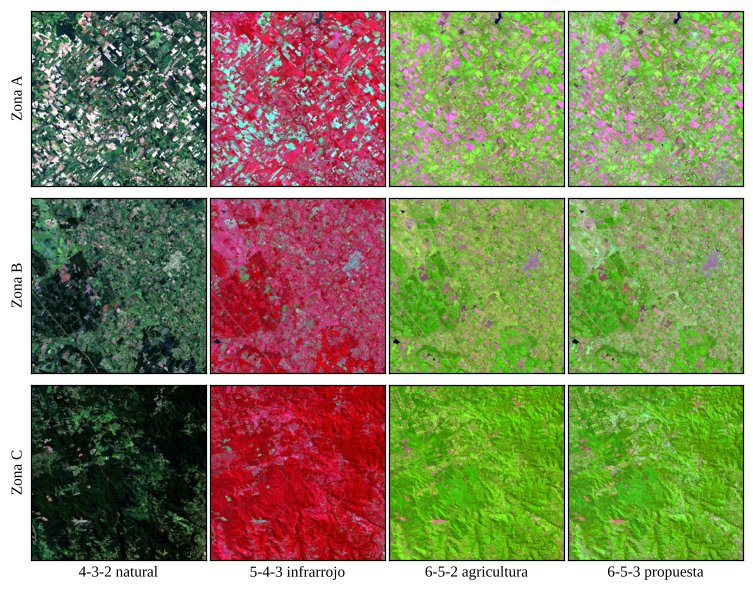

In [7]:
COMP = {"4-3-2 natural": (4, 3, 2), "5-4-3 infrarrojo": (5, 4, 3), "6-5-2 agricultura": (6, 5, 2),
        "6-5-4 vegetación": (6, 5, 4), "5-6-3": (5, 6, 3), "6-5-3 propuesta": (6, 5, 3)}
def lab(c): return cv2.cvtColor(c.astype(np.float32) / 255, cv2.COLOR_RGB2LAB)
def color(c, bb): return np.median(np.concatenate([lab(rgb(ventana(*v), *bb)).reshape(-1, 3) for v in MUESTRAS[c]]), 0)
print(f"{'Composición':<20}{'ΔE medio':>9}{'ΔE cultivo vigoroso / verde medio':>36}{'ΔE selva / pinar':>18}")
for n, bb in COMP.items():
    col = {p: color(p, bb) for p in COB}
    d = lambda a, b: np.linalg.norm(col[a] - col[b])
    print(f"{n:<20}{np.mean([d(a, b) for a, b in combinations(col, 2)]):>9.1f}"
          f"{d('Cultivo vigoroso', 'Cultivo verde medio'):>36.1f}{d('Selva', 'Pinar'):>18.1f}")

fig, ejes = plt.subplots(3, 4, figsize=(ANCHO, 5.25))
for j, n in enumerate(["4-3-2 natural", "5-4-3 infrarrojo", "6-5-2 agricultura", "6-5-3 propuesta"]):
    for i, k in enumerate("ABC"):
        mostrar_img(ejes[i, j], rgb({b: R[k][b][::2, ::2] for b in BANDAS}, *COMP[n]), n if i == 2 else "")
for i, k in enumerate("ABC"):
    ejes[i, 0].set_ylabel(f"Zona {k}")
guardar(fig, "composiciones"); plt.show()

**Resultado.**

- **Color natural:** la selva y el pinar quedan del mismo color (ΔE = 3,8).
- **5-4-3 (infrarrojo color):** separa los tipos de vegetación, pero tiene menos contraste general (ΔE medio 62).
- **NIR en el canal verde** (6-5-2, 6-5-4 y 6-5-3): el mayor contraste general (ΔE medio 75 a 78), y la vegetación se ve verde, lo que facilita la lectura. Selva y pinar quedan distintos (ΔE ≈ 14).
- **Qué banda va en el azul.** Con B3, el cultivo vigoroso y el verde medio quedan distintos (ΔE = 11,2). Con B2 o B4, como en las composiciones clásicas del anexo, quedan casi del mismo color (2,5 y 3,1).

**Conclusión.** Se elige **6-5-3: R = SWIR 1, G = NIR, B = verde**: entre las de mayor contraste (ΔE medio de 75 a 78) es la única que distingue los estados de cultivo.

**Cómo se lee:**

- Verde brillante: cultivo vigoroso, y también selva en laderas al sol.
- Verde medio con textura: selva y monte.
- Verde oscuro uniforme: pinares. La selva en laderas en sombra también se ve oscura, aunque con textura rugosa.
- Gris rosado: pastizal.
- Magenta: rastrojo o suelo.
- Violeta: ciudad.
- Azul oscuro: agua.

## 5. Mejora de contraste

Se comparan cuatro técnicas en la ROI C (selva): sin realce, estiramiento lineal por percentiles 2–98 % (calculados **dentro de la ROI** o **comunes a toda la escena**) y ecualización de histograma, que usa la **CDF** (*Cumulative Distribution Function*, distribución acumulada). La **entropía** mide cuántos de los 256 niveles se aprovechan (máximo 8 bits).

(a) Sin realce               entropía 5.38 bits · desvío 17
(b) Percentiles de la zona   entropía 7.73 bits · desvío 61
(c) Percentiles comunes      entropía 7.74 bits · desvío 64
(d) Ecualización             entropía 8.00 bits · desvío 74


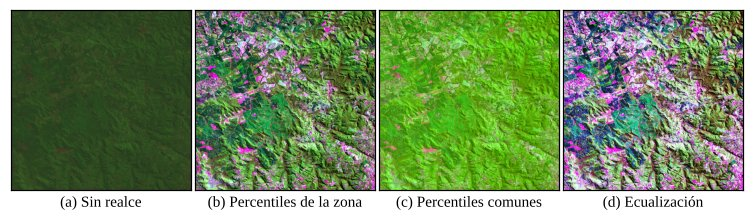

In [8]:
d = R["C"]
loc = {b: np.percentile(d[b], [2, 98]) for b in BANDAS}
def ecualizar(x):
    v = np.sort(x.ravel()); return np.round(np.searchsorted(v, x, side="right") / v.size * 255).astype(np.uint8)
VAR = {"(a) Sin realce": np.dstack([(d[b] >> 8).astype(np.uint8) for b in (6, 5, 3)]),
       "(b) Percentiles de la zona": rgb(d, 6, 5, 3, loc),
       "(c) Percentiles comunes": rgb(d, 6, 5, 3),
       "(d) Ecualización": np.dstack([ecualizar(d[b]) for b in (6, 5, 3)])}
def entropia(img):
    p = np.bincount(img.ravel(), minlength=256) / img.size; p = p[p > 0]; return -(p * np.log2(p)).sum()
fig, ejes = plt.subplots(1, 4, figsize=(ANCHO, 2.0))
for ax, (n, img) in zip(ejes, VAR.items()):
    mostrar_img(ax, img[::2, ::2], n)
    print(f"{n:<28} entropía {entropia(img):.2f} bits · desvío {img.std():.0f}")
guardar(fig, "realce"); plt.show()

**Resultado (ROI C).**

- **Sin realce:** la imagen es oscura (5,4 bits).
- **Percentiles de la propia ROI:** amplían las pequeñas variaciones de SWIR 1 dentro del bosque. La selva toma tonos pardos y blanquecinos, y las chacras se exageran en magenta.
- **Percentiles comunes a toda la escena:** mantienen la selva verde, con el mismo contraste (7,74 bits).
- **Ecualización:** máxima entropía (8,0 bits), pero tiñe la selva de azul, magenta y blanco. Los colores ya no tienen significado físico.

**Conclusión.** Se usa el **estiramiento lineal por percentiles 2–98 % calculados sobre toda la escena**. Así, un mismo color significa lo mismo en cualquier región, lo que es necesario para comparar zonas.

## 6. Agrupamiento con B3, B5 y B6

Para comprobar que lo que se ve no es una impresión del color, se agrupan los píxeles con **k-medias** (*k-means*), sin decirle qué es cada cosa. Antes hay que decidir dos cosas, y las dos se miden en lugar de fijarlas a ojo: **con qué variables** se agrupa y **cuántos grupos** (k) se piden. El agrupamiento se hace **una sola vez para las tres zonas juntas**, así cada grupo tiene el mismo significado y el mismo color en todas.

### 6.1 Efecto del relieve

La zona C es casi toda selva sobre sierras. Se toma el bosque de la sierra (píxeles con NDVI > 0,85, sin el cuadrante noroeste de la zona, que tiene chacras y plantaciones, y sin las áreas de muestra) y se comparan las laderas en sombra (15 % de píxeles con menor NIR) y al sol (15 % con mayor NIR). Además del NDVI se informan dos cocientes que usan solo las bandas del ejercicio: el **GNDVI** (*Green NDVI*, $(B5-B3)/(B5+B3)$) y el **NDMI** (*Normalized Difference Moisture Index*, $(B5-B6)/(B5+B6)$), que mide el agua de la vegetación.

In [9]:
f0, c0, n0 = REC["C"]
SIERRA = np.zeros((n0, n0), bool); SIERRA[300:, 300:] = True
for f, c, h, w in MUESTRAS["Selva"]:
    SIERRA[max(f - f0, 0):max(f - f0 + h, 0), max(c - c0, 0):max(c - c0 + w, 0)] = False
d = R["C"]; r = {b: rho(d[b]) for b in (3, 4, 5, 6)}
bos = SIERRA & (indice(r[5], r[4]) > 0.85)
nir = r[5][bos]; q15, q85 = np.percentile(nir, [15, 85])
SOMBRA, SOL = bos & (r[5] < q15), bos & (r[5] > q85)
print(f"Bosque de la sierra: {bos.sum():,} píxeles. NIR P5–P95: {np.percentile(nir, 5):.2f} a {np.percentile(nir, 95):.2f}".replace(",", "."))
lab_C = lab(rgb(d, 6, 5, 3)); suma = r[3] + r[5] + r[6]
col_ref = {p: color(p, (6, 5, 3)) for p in ("Pinar", "Cultivo vigoroso", "Selva")}
for nombre, m, ref in [("en sombra", SOMBRA, "Pinar"), ("al sol", SOL, "Cultivo vigoroso")]:
    X = np.stack([r[b][m] for b in (3, 5, 6)], 1); cm = np.median(lab_C[m], 0)
    print(f"Selva {nombre}: B3 {X[:, 0].mean():.3f}  NIR {X[:, 1].mean():.3f}  B6 {X[:, 2].mean():.3f}"
          f"  | proporción B3:B5:B6 = {(r[3] / suma)[m].mean():.3f} : {(r[5] / suma)[m].mean():.3f} : {(r[6] / suma)[m].mean():.3f}"
          f"  | NDVI {indice(r[5], r[4])[m].mean():.2f}  GNDVI {indice(r[5], r[3])[m].mean():.2f}  NDMI {indice(r[5], r[6])[m].mean():.2f}")
    print("   ΔE en 6-5-3 con " + ", ".join(f"{p.lower()} {np.linalg.norm(cm - col_ref[p]):.1f}" for p in col_ref))
    print(f"   S con {ref.lower()}: " + "  ".join(f"B{b} {sep(X[:, i], MUE[ref][b]):.2f}" for i, b in enumerate((3, 5, 6))) +
          f"  | B3+B5+B6 combinadas {fisher(X, X3m(ref)):.2f}")

Bosque de la sierra: 402.339 píxeles. NIR P5–P95: 0.21 a 0.40
Selva en sombra: B3 0.021  NIR 0.218  B6 0.086  | proporción B3:B5:B6 = 0.063 : 0.673 : 0.263  | NDVI 0.90  GNDVI 0.83  NDMI 0.44
   ΔE en 6-5-3 con pinar 11.4, cultivo vigoroso 56.9, selva 22.2
   S con pinar: B3 1.24  B5 0.80  B6 0.31  | B3+B5+B6 combinadas 2.13
Selva al sol: B3 0.037  NIR 0.397  B6 0.154  | proporción B3:B5:B6 = 0.062 : 0.676 : 0.262  | NDVI 0.90  GNDVI 0.83  NDMI 0.44
   ΔE en 6-5-3 con pinar 34.6, cultivo vigoroso 13.2, selva 21.7
   S con cultivo vigoroso: B3 0.47  B5 0.97  B6 0.28  | B3+B5+B6 combinadas 1.28


**Resultado.**

- En el bosque de la sierra el NIR va de 0,21 a 0,40 según la ladera: casi el doble.
- La **selva en sombra** (NIR 0,22, B6 0,09) se parece al pinar: en la composición 6-5-3 su color queda a ΔE = 11,4 del pinar, apenas por encima del umbral de 10, y en B5 y B6 la separabilidad es de 0,80 y 0,31. Pero **combinando las tres bandas S = 2,13**: la diferencia está en la proporción entre bandas (el pinar tiene menos SWIR 1 en relación con el NIR).
- La **selva al sol** (NIR 0,40) se parece más al cultivo vigoroso (ΔE = 13,2) que al color típico de la selva (ΔE = 21,7). Combinando las tres bandas, S = 1,28: es el par más difícil de la vegetación densa.
- Las **proporciones** entre B3, B5 y B6 son las mismas en sombra y al sol (0,063 : 0,673 : 0,263 y 0,062 : 0,676 : 0,262): la ladera multiplica las tres bandas por casi el mismo factor. Por eso los cocientes (NDVI, GNDVI y NDMI) **no cambian** con la iluminación.

**Conclusión.** En una sierra la reflectancia depende tanto de la cobertura como de la orientación de la ladera respecto del Sol (que estaba a 45° de altura). Con una banda sola o a simple vista, la selva en sombra se parece al pinar y la selva al sol a un cultivo. Con las tres bandas combinadas la selva en sombra se separa bien del pinar, y la selva al sol solo en parte del cultivo vigoroso.

### 6.2 Variables y número de grupos

Se comparan dos juegos de variables: las **reflectancias** de B3, B5 y B6, y los **cocientes** GNDVI y NDMI. Para cada k de 2 a 8 se mide:

- **Inercia:** distancia cuadrática media de cada píxel al centro de su grupo. Siempre baja al aumentar k; el k adecuado está en el **codo**, donde agregar un grupo deja de mejorarla mucho.
- **Silueta:** para cada píxel compara la distancia media a su grupo ($a$) con la del grupo más cercano ($b$): $s = (b - a) / \max(a, b)$. Vale 1 si los grupos están bien separados y 0 si se tocan.
- **Coincidencia sombra / sol:** qué parte de la selva en sombra y de la selva al sol cae en los mismos grupos (100 % = el relieve no influye).

El agua se separa antes por regla (NIR < 0,05), como en la sección 7.

In [10]:
def bandas(d): return np.nan_to_num(np.dstack([rho(d[b]) for b in (3, 5, 6)])).reshape(-1, 3).astype(np.float32)
def cocientes(d):
    r = {b: rho(d[b]) for b in (3, 5, 6)}
    return np.nan_to_num(np.dstack([indice(r[5], r[3]), indice(r[5], r[6])])).reshape(-1, 2).astype(np.float32)
AGUA = {k: np.nan_to_num(rho(R[k][5])).ravel() < 0.05 for k in "ABC"}
sel_m = np.random.default_rng(0).choice(sum((~a).sum() for a in AGUA.values()), 300_000, replace=False)
def muestra(F): return np.concatenate([F(R[k])[~AGUA[k]] for k in "ABC"])[sel_m]

def kmedias(X, k):
    cv2.setRNGSeed(0)
    inercia, et, cen = cv2.kmeans(X, k, None, (3, 100, 1e-5), 5, cv2.KMEANS_PP_CENTERS)
    return inercia / len(X), et.ravel(), cen
def asignar(X, cen): return ((X[:, None, :] - cen[None]) ** 2).sum(-1).argmin(1)
def silueta(X, et, n=4000):
    X, et = X[:n].astype(np.float64), et[:n]
    D = np.sqrt(np.maximum((X * X).sum(1)[:, None] + (X * X).sum(1)[None] - 2 * X @ X.T, 0))
    M = np.stack([D[:, et == g].mean(1) for g in range(et.max() + 1)], 1)
    tam = np.bincount(et)[et]
    a = M[np.arange(len(X)), et] * tam / np.maximum(tam - 1, 1)
    M[np.arange(len(X)), et] = np.inf
    b = M.min(1)
    return np.mean((b - a) / np.maximum(a, b))
def coincidencia(F, cen):
    X = F(R["C"]); k = len(cen)
    p = [np.bincount(asignar(X[m.ravel()], cen), minlength=k) / m.sum() for m in (SOMBRA, SOL)]
    return np.minimum(*p).sum() * 100

print(f"{'':>3}{'Reflectancias B3, B5, B6':^34}{'Cocientes GNDVI, NDMI':^34}")
print(f"{'k':>3}" + f"{'inercia':>11}{'silueta':>10}{'sombra/sol':>13}" * 2)
for k in range(2, 9):
    fila = f"{k:>3}"
    for F in (bandas, cocientes):
        X = muestra(F); inercia, et, cen = kmedias(X, k)
        fila += f"{inercia:>11.5f}{silueta(X, et):>10.2f}{coincidencia(F, cen):>11.0f} %"
    print(fila)

        Reflectancias B3, B5, B6           Cocientes GNDVI, NDMI       
  k    inercia   silueta   sombra/sol    inercia   silueta   sombra/sol


  2    0.00510      0.38        100 %    0.01522      0.60        100 %


  3    0.00305      0.37          0 %    0.00653      0.58         99 %


  4    0.00241      0.33          0 %    0.00439      0.50         96 %


  5    0.00191      0.35          0 %    0.00311      0.46         97 %


  6    0.00159      0.36          0 %    0.00237      0.46         97 %


  7    0.00138      0.34          0 %    0.00192      0.44         93 %


  8    0.00120      0.34          0 %    0.00162      0.43         92 %


**Resultado.**

- Con las **reflectancias**, desde k = 3 la selva en sombra y la selva al sol caen en grupos distintos (coincidencia 0 %): k-medias no conoce la variación de cada cobertura, y la mayor diferencia entre píxeles es el brillo, que en la sierra depende de la ladera. El agrupamiento separa laderas, no coberturas.
- Con los **cocientes** la coincidencia es del 92 al 100 % para todo k, y la silueta es mayor (0,58 contra 0,37 con k = 3).
- **Número de grupos:** la inercia baja un 57 % de k = 2 a 3 y después cada vez menos (33, 29, 24 %…). La silueta se mantiene en 0,60–0,58 hasta k = 3 y cae a 0,50 con k = 4.

**Conclusión.** Se agrupa con los cocientes y **k = 3**. Con k = 2 solo se separa la vegetación densa del resto. Pedir más grupos no encuentra coberturas nuevas, solo parte en pedazos una nube continua de valores.

### 6.3 Grupos

Grupo    GNDVI   NDMI  NIR medio   % zona A   % zona B   % zona C   % selva en sombra   % selva al sol
G1        0.50  -0.08      0.223      24.9 %       7.2 %       1.4 %               0 %             0 %
G2        0.71   0.24      0.304      33.9 %      56.4 %      14.6 %               2 %             0 %
G3        0.81   0.44      0.320      41.0 %      36.3 %      84.0 %              98 %           100 %
Cocientes medios de las muestras:
   Selva              GNDVI 0.84  NDMI 0.42
   Pinar              GNDVI 0.80  NDMI 0.53
   Cultivo vigoroso   GNDVI 0.83  NDMI 0.49


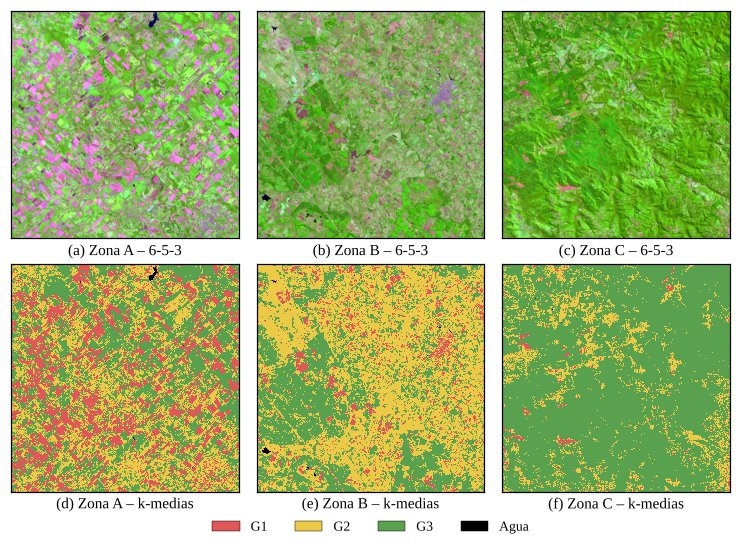

In [11]:
K = 3
_, _, CEN = kmedias(muestra(cocientes), K)
CEN = CEN[np.argsort(CEN.sum(1))]   # de menos a más vegetación
COL_G = ["#E15759", "#EDC948", "#59A14F"]
GRUPOS = {}
for k in "ABC":
    g = asignar(cocientes(R[k]), CEN); g[AGUA[k]] = -1; GRUPOS[k] = g.reshape(R[k][3].shape)
print(f"{'Grupo':<7}{'GNDVI':>7}{'NDMI':>7}{'NIR medio':>11}   % zona A   % zona B   % zona C   % selva en sombra   % selva al sol")
for g, c in enumerate(CEN):
    sel = {k: GRUPOS[k] == g for k in "ABC"}
    nirm = np.nanmean(np.concatenate([rho(R[k][5])[sel[k]] for k in "ABC"]))
    print(f"G{g + 1:<6}{c[0]:>7.2f}{c[1]:>7.2f}{nirm:>11.3f}" + "".join(f"{sel[k].mean() * 100:>10.1f} %" for k in "ABC") +
          f"{(GRUPOS['C'][SOMBRA] == g).mean() * 100:>16.0f} %{(GRUPOS['C'][SOL] == g).mean() * 100:>14.0f} %")
print("Cocientes medios de las muestras:")
for c in ("Selva", "Pinar", "Cultivo vigoroso"):
    print(f"   {c:<18} GNDVI {np.nanmean(indice(MUE[c][5], MUE[c][3])):.2f}  NDMI {np.nanmean(indice(MUE[c][5], MUE[c][6])):.2f}")

fig, ejes = plt.subplots(2, 3, figsize=(ANCHO, 4.85))
for j, k in enumerate("ABC"):
    pint = np.zeros(GRUPOS[k].shape + (3,), np.uint8)
    for g, c in enumerate(COL_G):
        pint[GRUPOS[k] == g] = np.array(plt.matplotlib.colors.to_rgb(c)) * 255
    mostrar_img(ejes[0, j], rgb(R[k], 6, 5, 3)[::2, ::2], f"({'abc'[j]}) Zona {k} – 6-5-3")
    mostrar_img(ejes[1, j], pint[::2, ::2], f"({'def'[j]}) Zona {k} – k-medias", interpolation="nearest")
fig.legend(handles=[Patch(fc=c, ec="k", lw=.3, label=f"G{i + 1}") for i, c in enumerate(COL_G)] +
           [Patch(fc="k", ec="k", lw=.3, label="Agua")], loc="outside lower center", ncol=4, frameon=False)
guardar(fig, "kmedias"); plt.show()

**Resultado.** Interpretación de cada grupo (a partir de sus cocientes y de la composición) y porcentaje de cada zona:

| Grupo | Interpretación | Zona A | Zona B | Zona C |
|---|---|---|---|---|
| G1 | Suelo desnudo, rastrojo y ciudad | 25 % | 7 % | 1 % |
| G2 | Vegetación intermedia: pastizal, cultivo en desarrollo o maduro, claros | 34 % | 56 % | 15 % |
| G3 | Vegetación densa y saludable: selva, monte, forestación y cultivo vigoroso | 41 % | 36 % | 84 % |

- **Zona A:** el ciclo agrícola se reparte en los tres grupos, con lotes enteros de un mismo grupo.
- **Zona B:** domina el pastizal (G2). Las forestaciones y el monte en galería caen en G3.
- **Zona C:** el **84 %** es vegetación densa (G3), y ahí están el 98 % de la selva en sombra y el 100 % de la selva al sol. El G2 de la zona C son los claros y chacras del noroeste y algunos claros dentro de la sierra.

**Conclusión.** La separación entre suelo, vegetación intermedia y vegetación densa está en los datos y no solo en el color. Dentro de G3, selva, pinar y cultivo vigoroso tienen cocientes cercanos (GNDVI 0,80 a 0,84 y NDMI 0,42 a 0,53) comparados con la distancia entre grupos, y no forman grupos propios. Para separarlos hacen falta muestras de cada clase (sección 7).

## 7. Clasificación supervisada

Para ubicar los objetivos en la escena se usa una **clasificación supervisada de máxima verosimilitud** con B3, B5 y B6, entrenada con las áreas de muestra de la sección 2:

1. De cada clase se calcula su firma media μ y su covarianza Σ.
2. Cada píxel se asigna a la clase más probable según la **distancia de Mahalanobis** $D^2=(x-\mu)^\top\Sigma^{-1}(x-\mu)$, que tiene en cuenta las tres bandas juntas y cómo varían dentro de cada clase.
3. Si queda demasiado lejos de todas ($D^2 > \chi^2_{0,999} = 16{,}27$ con 3 variables), queda sin clasificar.
4. El agua (NIR < 0,05) se asigna por regla.
5. Un **filtro de mayoría** 3 × 3 elimina los píxeles sueltos.

Se prueban dos mejoras, pensadas para el efecto del relieve, y se evalúan en **16 áreas de validación** que no se usaron para entrenar:

- **Subclases de selva.** La selva varía mucho con la iluminación, y una sola clase con toda esa variación queda muy ancha: la selva en sombra cae en un extremo de su distribución, mientras que el pinar, más compacto, resulta más probable. Se divide la selva en 3 subclases según el brillo (tercios del NIR de sus muestras) y al final se unen.
- **Textura** (sección 7.1).

### 7.1 Textura

Una plantación es pareja, mientras que la selva sobre relieve alterna laderas al sol y en sombra en pocas decenas de metros. Se mide con el **coeficiente de variación local** del NIR en una ventana de 9 × 9 píxeles (270 m): $\sigma_{local} / \mu_{local}$, calculado con dos filtros de promedio (de la imagen y de su cuadrado). No se usa como cuarta variable de la clasificación, porque las áreas de muestra chicas no representan bien la textura de clases como el rastrojo, sino solo para decidir entre pinar y selva: un píxel clasificado como pinar pasa a selva si su textura supera $\mu + 2\sigma$ de la textura del pinar.

La textura es una propiedad del entorno de cada píxel, y en una plantación real el entorno incluye cortafuegos y bordes de bloque. Por eso el umbral se calcula con los píxeles de pinar de **bloques de 60 × 60 píxeles** (1,8 km) alrededor de cada área de muestra, y no solo con el interior de los compartimentos.

In [12]:
W = 9
nirF = np.nan_to_num(rho(FULL[5]))
mu = cv2.blur(nirF, (W, W)); sd = np.sqrt(np.maximum(cv2.blur(nirF * nirF, (W, W)) - mu * mu, 0))
TEX = (sd / np.maximum(mu, 1e-3)).astype(np.float32)
del nirF, mu, sd
def tex_clase(c): return np.concatenate([TEX[f:f + h, cc:cc + w].ravel() for f, cc, h, w in MUESTRAS[c]])
NDVI_F = indice(rho(FULL[5]), rho(FULL[4]))
def bloque(f, c, h, w, L=60):   # píxeles de pinar de un bloque de L × L alrededor de un área (sin cortafuegos ni bordes)
    m = np.zeros(TEX.shape, bool); f0_, c0_ = f + h // 2 - L // 2, c + w // 2 - L // 2; m[f0_:f0_ + L, c0_:c0_ + L] = True
    return m & (NDVI_F > 0.8) & (rho(FULL[5]) < 0.30)
BLOQUES = np.any([bloque(*v) for v in MUESTRAS["Pinar"]], 0)
tC = TEX[f0:f0 + n0, c0:c0 + n0]; tP = tex_clase("Pinar"); tB = TEX[BLOQUES]
for nombre, v in [("Pinar (áreas de muestra)", tP), ("Pinar (bloques de 60 × 60)", tB), ("Selva (muestras)", tex_clase("Selva")),
                  ("Selva en sombra (sierra)", tC[SOMBRA]), ("Selva al sol (sierra)", tC[SOL])]:
    print(f"{nombre:<28} textura {v.mean():.3f} ± {v.std():.3f}")
for nombre, u in [("áreas de muestra", tP.mean() + 2 * tP.std()), ("bloques", tB.mean() + 2 * tB.std())]:
    print(f"Umbral μ + 2σ con {nombre}: {u:.3f} → conserva el {(tB < u).mean() * 100:.0f} % del pinar de los bloques"
          f" y marca el {(tC[SOMBRA] > u).mean() * 100:.0f} % de la selva en sombra")
UMBRAL_TEX = tB.mean() + 2 * tB.std()
Xs = np.stack([r[b][SOMBRA] for b in (3, 5, 6)], 1)
print(f"Separabilidad selva en sombra / pinar: textura sola {sep(tC[SOMBRA], tP):.2f} · B3+B5+B6 {fisher(Xs, X3m('Pinar')):.2f}"
      f" · B3+B5+B6+textura {fisher(np.c_[Xs, tC[SOMBRA]], np.c_[X3m('Pinar'), tP]):.2f}")
print(f"Umbral usado (bloques): {UMBRAL_TEX:.3f}")

Pinar (áreas de muestra)     textura 0.041 ± 0.020
Pinar (bloques de 60 × 60)   textura 0.065 ± 0.036
Selva (muestras)             textura 0.119 ± 0.050
Selva en sombra (sierra)     textura 0.170 ± 0.055
Selva al sol (sierra)        textura 0.133 ± 0.047
Umbral μ + 2σ con áreas de muestra: 0.080 → conserva el 71 % del pinar de los bloques y marca el 97 % de la selva en sombra
Umbral μ + 2σ con bloques: 0.136 → conserva el 95 % del pinar de los bloques y marca el 71 % de la selva en sombra
Separabilidad selva en sombra / pinar: textura sola 1.72 · B3+B5+B6 2.13 · B3+B5+B6+textura 2.55
Umbral usado (bloques): 0.136


### 7.2 Validación

In [13]:
X3 = lambda d: np.nan_to_num(np.dstack([rho(d[b]) for b in (3, 5, 6)]))
def entrenar(nsub):
    MU, IC, LD, ET = [], [], [], []
    for i, c in enumerate(CL):
        X = X3m(c); partes = [X]
        if c == "Selva" and nsub > 1:   # subclases por tercios de brillo (NIR)
            q = np.quantile(X[:, 1], np.linspace(0, 1, nsub + 1)); q[-1] += 1
            partes = [X[(X[:, 1] >= q[j]) & (X[:, 1] < q[j + 1])] for j in range(nsub)]
        for Xp in partes:
            Sg = np.cov(Xp.T) + np.eye(3) * 1e-4
            MU.append(Xp.mean(0)); IC.append(np.linalg.inv(Sg)); LD.append(np.linalg.slogdet(Sg)[1]); ET.append(i)
    return MU, IC, LD, np.array(ET)

def clasificar(d, modelo, tex=None, filtro=3):
    MU, IC, LD, ET = modelo
    X = X3(d); sh = X.shape[:2]; X = X.reshape(-1, 3); k = np.empty(len(X), int)
    for i in range(0, len(X), 10**6):
        x = X[i:i + 10**6]
        D = np.stack([np.einsum("ij,jk,ik->i", x - m, ic, x - m) for m, ic in zip(MU, IC)], 1)
        j = np.argmax(-.5 * (D + LD), 1); kk = ET[j]; kk[D[np.arange(len(j)), j] > 16.27] = -1
        kk[x[:, 1] < .05] = CL.index("Agua"); k[i:i + 10**6] = kk
    k = k.reshape(sh)
    if tex is not None:   # pinar con textura de selva -> selva
        k[(k == CL.index("Pinar")) & (tex > UMBRAL_TEX)] = CL.index("Selva")
    if filtro:            # filtro de mayoría
        votos = np.stack([cv2.blur((k == c).astype(np.float32), (filtro, filtro)) for c in range(-1, len(CL))], -1)
        k = votos.argmax(-1) - 1
    return k

VARIANTES = {"Selva en una clase": (entrenar(1), False), "Subclases": (entrenar(3), False), "Subclases + textura": (entrenar(3), True)}
def aplicar(f, c, h, w, variante):
    modelo, usa_tex = VARIANTES[variante]
    return clasificar(ventana(f, c, h, w), modelo, TEX[f:f + h, c:c + w] if usa_tex else None)

VALID = {"Agua – Paraná": ("Agua", (2190, 3700, 15, 15)), "Agua – embalse BR": ("Agua", (6546, 4795, 15, 15)),
         "Selva al sol": ("Selva", (2735, 5065, 20, 20)), "Selva con relieve": ("Selva", (2805, 4860, 60, 100)),
         "Monte": ("Selva", (2130, 5220, 30, 30)), "Cultivo vigoroso PY": ("Cultivo vigoroso", (1198, 3644, 15, 15)),
         "Pivote de riego BR": ("Cultivo vigoroso", (7077, 4489, 15, 15)), "Rastrojo PY": ("Rastrojo / suelo", (2004, 3803, 15, 15)),
         "Rastrojo BR": ("Rastrojo / suelo", (7209, 4589, 15, 15)), "Ciudad": ("Urbano", (1615, 4885, 25, 25)),
         "Pinar 1": ("Pinar", (5253, 452, 14, 14)), "Pinar 2": ("Pinar", (5000, 742, 16, 16)),
         "Pinar 3": ("Pinar", (6476, 723, 12, 12)), "Pinar 4": ("Pinar", (5491, 513, 14, 14)),
         "Pastizal 1": ("Pastizal", (5930, 260, 20, 20)), "Pastizal 2": ("Pastizal", (6110, 480, 20, 20))}
print(f"{'Área de validación':<24}" + "".join(f"{v:>22}" for v in VARIANTES))
acierto = {v: [] for v in VARIANTES}
for n, (c, (f, cc, h, w)) in VALID.items():
    fila = f"{n:<24}"
    for v in VARIANTES:
        a = (aplicar(f - 3, cc - 3, h + 6, w + 6, v)[3:-3, 3:-3] == CL.index(c)).mean() * 100
        acierto[v].append(a); fila += f"{a:>21.0f}%"
    print(fila)
print(f"{'Acierto promedio':<24}" + "".join(f"{np.mean(acierto[v]):>21.0f}%" for v in VARIANTES))
BLOQUES_V = np.any([bloque(*VALID[f"Pinar {i}"][1]) for i in range(1, 5)], 0)   # bloques completos de las plantaciones de validación
fila = f"{'Bloques de pinar (val.)':<24}"
for v in VARIANTES:
    ks = [aplicar(*(lambda f, c, h, w: (f + h // 2 - 33, c + w // 2 - 33, 66, 66))(*VALID[f"Pinar {i}"][1]), v) for i in range(1, 5)]
    ms = [(lambda f, c, h, w: BLOQUES_V[f + h // 2 - 33:f + h // 2 + 33, c + w // 2 - 33:c + w // 2 + 33])(*VALID[f"Pinar {i}"][1]) for i in range(1, 5)]
    fila += f"{np.mean(np.concatenate([k[m] for k, m in zip(ks, ms)]) == CL.index('Pinar')) * 100:>21.0f}%"
print(fila)
print("\nBosque de la sierra (zona C):")
for v in VARIANTES:
    kC = aplicar(f0, c0, n0, n0, v); fb, cb, nb = REC["B"]; kB = aplicar(fb, cb, nb, nb, v)
    cult = np.isin(kC[SOL], [CL.index("Cultivo verde medio"), CL.index("Cultivo vigoroso")]).mean() * 100
    print(f"{v:<22} sombra: {(kC[SOMBRA] == CL.index('Selva')).mean() * 100:3.0f} % selva, {(kC[SOMBRA] == CL.index('Pinar')).mean() * 100:3.0f} % pinar"
          f" | sol: {(kC[SOL] == CL.index('Selva')).mean() * 100:3.0f} % selva, {cult:3.0f} % cultivo"
          f" | pinar en la zona B {(kB == CL.index('Pinar')).mean() * 100:4.1f} %, en la zona C {(kC == CL.index('Pinar')).mean() * 100:4.1f} %")

def reparto(k):   # porcentaje de cada clase asignada
    u, n = np.unique(k, return_counts=True)
    return ", ".join(f"{(CL[i] if i >= 0 else 'Sin clasificar').lower()} {c / k.size * 100:.0f} %"
                     for i, c in sorted(zip(u, n), key=lambda x: -x[1]) if c / k.size >= 0.01)
print("\nCon subclases y textura:")
for n in ("Pastizal 1", "Pastizal 2"):
    f, cc, h, w = VALID[n][1]
    print(f"   {n} (validación):", reparto(aplicar(f - 3, cc - 3, h + 6, w + 6, "Subclases + textura")[3:-3, 3:-3]))
print("   Selva al sol de la sierra:", reparto(aplicar(f0, c0, n0, n0, "Subclases + textura")[SOL]))

Área de validación          Selva en una clase             Subclases   Subclases + textura
Agua – Paraná                             100%                  100%                  100%
Agua – embalse BR                         100%                  100%                  100%
Selva al sol                              100%                  100%                  100%
Selva con relieve                          82%                   92%                   95%
Monte                                      90%                   97%                   97%
Cultivo vigoroso PY                       100%                  100%                  100%
Pivote de riego BR                        100%                  100%                  100%
Rastrojo PY                                98%                   98%                   98%
Rastrojo BR                               100%                  100%                  100%
Ciudad                                     93%                   93%                   93%

Bloques de pinar (val.)                    96%                   93%                   92%

Bosque de la sierra (zona C):


Selva en una clase     sombra:  58 % selva,  42 % pinar | sol:  52 % selva,  46 % cultivo | pinar en la zona B  8.3 %, en la zona C 17.3 %


Subclases              sombra:  85 % selva,  15 % pinar | sol:  71 % selva,  28 % cultivo | pinar en la zona B  6.6 %, en la zona C 11.8 %


Subclases + textura    sombra:  93 % selva,   7 % pinar | sol:  71 % selva,  28 % cultivo | pinar en la zona B  5.1 %, en la zona C  8.5 %

Con subclases y textura:
   Pastizal 1 (validación): pastizal 100 %
   Pastizal 2 (validación): pastizal 100 %


   Selva al sol de la sierra: selva 71 %, cultivo verde medio 23 %, cultivo vigoroso 5 %, pastizal 1 %


**Resultado.**

- El **acierto promedio** es del 98 al 99 % en las tres variantes: las mejoras cambian pocas áreas, pero justo las del problema del relieve.
- **Selva en sombra:** con la selva en una sola clase, el 42 % se clasifica como pinar. Con subclases baja al 15 %, y con la textura al 7 %. La selva con relieve pasa de 82 a 92 y a 95 %.
- **Pinar:** las cuatro áreas de validación quedan entre 99 y 100 % en las tres variantes. En los bloques completos, donde hay cortafuegos y bordes cerca, se clasifica como pinar el 96, 93 y 92 %: las mejoras le cuestan poco a la plantación.
- **Umbral de textura:** calculado solo con el interior de los compartimentos (0,080) marcaría el 97 % de la selva en sombra, pero borraría el 29 % del pinar de los bloques. Con los bloques (0,136) se conserva el 95 % del pinar y se marca el 71 % de la selva en sombra.
- **Selva al sol:** las subclases la suben de 52 a 71 %, pero el 28 % sigue como cultivo, sobre todo cultivo verde medio. La textura no ayuda ahí, porque las laderas al sol también son rugosas (0,13).

**Conclusión.** Para la selva en sombra el problema no eran las bandas, que la separan del pinar (S = 2,13), sino cómo se modelaba la selva: una sola clase con toda la variación de iluminación. Las subclases resuelven buena parte y la textura agrega otro poco. La selva al sol contra el cultivo vigoroso (S = 1,28) es el límite de estas bandas en una sola fecha.

### 7.3 Escena completa

Se aplica la variante con subclases y textura a toda la escena (a 60 m, un píxel de cada dos).

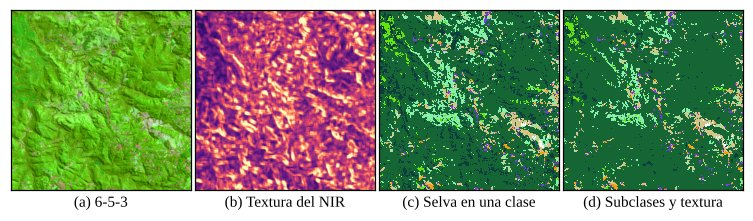

Agua                     1.052 km²  ( 2.9 %)
Urbano                   1.644 km²  ( 4.5 %)
Rastrojo / suelo         1.713 km²  ( 4.6 %)
Vegetación rala          2.710 km²  ( 7.3 %)
Pastizal                10.130 km²  (27.5 %)


Cultivo verde medio      1.592 km²  ( 4.3 %)
Cultivo vigoroso           508 km²  ( 1.4 %)
Selva                   16.099 km²  (43.6 %)
Pinar                    1.051 km²  ( 2.8 %)
Sin clasificar                       1.0 %


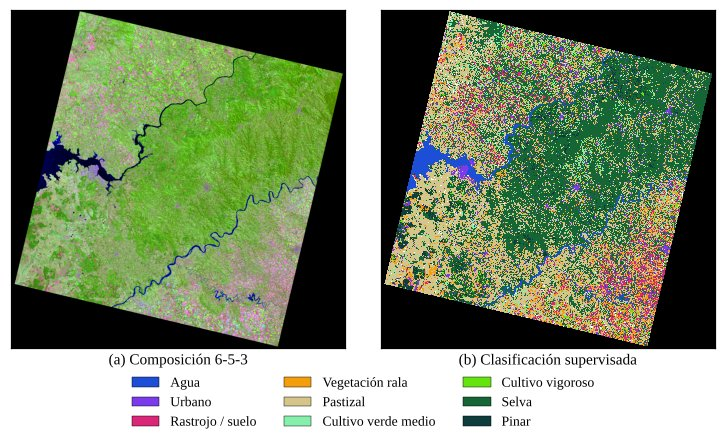

In [14]:
COLC = {"Agua": "#1d4ed8", "Urbano": "#7c3aed", "Rastrojo / suelo": "#db2777", "Vegetación rala": "#f59e0b",
        "Pastizal": "#d6c58a", "Cultivo verde medio": "#86efac", "Cultivo vigoroso": "#65e30d",
        "Selva": "#166534", "Pinar": "#0f3d3e"}
def pintar(m):
    p = np.full(m.shape + (3,), 255, np.uint8); p[m == -2] = 0
    for i, c in enumerate(CL): p[m == i] = np.array(plt.matplotlib.colors.to_rgb(COLC[c])) * 255
    return p

# Detalle de la zona C (15 × 15 km): una clase de selva contra subclases y textura
f, c, n = f0 + 450, c0 + 450, 500   # sector con relieve marcado
fig, ejes = plt.subplots(1, 4, figsize=(ANCHO, 2.05))
mostrar_img(ejes[0], rgb(ventana(f, c, n, n), 6, 5, 3), "(a) 6-5-3")
mostrar_img(ejes[1], TEX[f:f + n, c:c + n], "(b) Textura del NIR", cmap="magma", vmin=0, vmax=0.25)
mostrar_img(ejes[2], pintar(aplicar(f, c, n, n, "Selva en una clase")), "(c) Selva en una clase", interpolation="nearest")
mostrar_img(ejes[3], pintar(aplicar(f, c, n, n, "Subclases + textura")), "(d) Subclases y textura", interpolation="nearest")
guardar(fig, "textura"); plt.show()

modelo, _ = VARIANTES["Subclases + textura"]
MAPA = clasificar(E, modelo, TEX[::PASO, ::PASO]); MAPA[~VAL_E] = -2
km2 = (30 * PASO) ** 2 / 1e6
for i, c in enumerate(CL):
    print(f"{c:<22}{(MAPA == i).sum() * km2:>8,.0f} km²  ({(MAPA == i).sum() / (MAPA >= -1).sum() * 100:4.1f} %)".replace(",", "."))
print(f"{'Sin clasificar':<22}{(MAPA == -1).sum() / (MAPA >= -1).sum() * 100:>18.1f} %")
fig, ejes = plt.subplots(1, 2, figsize=(ANCHO, 3.9))
mostrar_img(ejes[0], rgb({b: E[b][::2, ::2] for b in BANDAS}, 6, 5, 3), "(a) Composición 6-5-3")
mostrar_img(ejes[1], pintar(MAPA)[::2, ::2], "(b) Clasificación supervisada", interpolation="nearest")
fig.legend(handles=[Patch(fc=COLC[c], ec="k", lw=.3, label=c) for c in CL], loc="outside lower center", ncol=3, frameon=False, fontsize=9)
guardar(fig, "clasificacion"); plt.show()

**Resultado.**

- **Vegetación densa y saludable:** unos **16.100 km² de selva y monte**, en un bloque continuo sobre la Sierra Central de Misiones, unos **1.050 km² de pinar**, sobre todo en Corrientes, y unos **510 km² de cultivo vigoroso**.
- **Cultivos:** dos polos agrícolas, Itapúa y el noroeste de Rio Grande do Sul. En Brasil predominan el rastrojo y la vegetación rala: la cosecha estaba más avanzada.
- **Errores conocidos:** parte de la selva en laderas al sol figura como cultivo verde medio, y la clase urbana (1.640 km²) aparece también en píxeles sueltos de las zonas agrícolas del sureste, donde no hay ciudades.

## 8. Discusión y conclusión

**¿Alcanza la resolución de 30 m?** Alcanza para lotes mecanizados (10 a 50 ha, cientos de píxeles) y bloques forestales. Está en el límite para las chacras misioneras (1 a 5 ha, con muchos píxeles mixtos en los bordes). No alcanza para hileras de yerba o té, árboles aislados o caminos. La pancromática de 15 m no lo resuelve, porque el NIR y el SWIR 1 siguen a 30 m.

**Desafíos.**

- Un tercio de la escena es relleno sin dato: el notebook de la cátedra calcula los percentiles incluyéndolo, y el percentil 2 da 0.
- El estiramiento por región cambia el significado de los colores.
- **Muestras representativas:** la separabilidad y la clasificación dependen de que las muestras cubran toda la variación de cada cobertura. Con una sola área de selva y una de pinar, el NIR parecía separarlas; las áreas con cortafuegos o con dos campos distintos falseaban la textura y la validación; y con la selva modelada como una sola clase, la selva en sombra se clasificaba como pinar.
- **El relieve:** con una banda sola o a simple vista, la selva en sombra se confunde con el pinar y la selva al sol con un cultivo. Las tres bandas combinadas separan la primera (S = 2,13) y solo en parte la segunda (S = 1,28).
- **Separabilidad de a una variable:** S por banda subestima lo que separan las tres bandas juntas; hay que medirla también combinada (discriminante de Fisher).
- **El número de grupos:** se eligió con la silueta y el codo de la inercia; los datos tienen tres grupos naturales.
- El NDVI se satura en la vegetación densa.

**Mejoras posibles.**

- Un modelo de elevación del terreno para corregir la iluminación de cada ladera.
- Varias fechas, para identificar especies por su fenología.
- Datos de campo para validar, y más áreas de muestra para los estados de cultivo.
- Delimitar los bloques forestales completos para validar la textura sobre plantaciones enteras.
- Sensores con bandas de borde rojo y 10–20 m de resolución, como Sentinel-2.

**Conclusión.** La composición **6-5-3 con estiramiento por percentiles comunes** resalta la vegetación densa y saludable y separa estados de cultivo, monte, forestaciones y pastizal. Las tres bandas combinadas separan todas las coberturas estudiadas, pero ninguna lo hace sola. En las sierras la iluminación de las laderas cambia la firma de la selva: a simple vista la selva en sombra se confunde con el pinar, aunque con las tres bandas, subclases de iluminación y la textura la clasificación la recupera (93 %). La selva al sol se sigue confundiendo en parte con el cultivo (71 % de acierto), que es el límite de estas bandas en una sola fecha.